# Geo spend bundles with randomized markets

You can move budget from TV to search and use a reserve to add video. Before you spend the reserve, you want to know whether video pays off alongside the search and TV changes. If every market gets the full plan or stays at usual spend, you can learn about the full plan. To learn what the reserve buys, you need markets that run the search and TV reallocation without video.

Design the geo trial around the comparison you need. This example uses assigned arms to estimate bundle-level and video contrasts. It also uses CausalPy's {class}`~causalpy.SyntheticControl` to illustrate gaps for individual treated markets. The {doc}`national spend bundles example <interrupted-time-series-national-spend-bundles-pymc>` follows the same plan when you have one national launch.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from scipy.stats import norm

import causalpy as cp

%matplotlib inline
%config InlineBackend.figure_format = "retina"

logging.getLogger("pymc").setLevel(logging.WARNING)
plt.style.use("seaborn-v0_8-whitegrid")
FIG_WIDTH, FIG_HEIGHT = 8, 3.2
ESTIMATE_COLOR, OBSERVED_COLOR = "#0072B2", "#252525"
POST_WEEKS = 12
GEO_SEED, PANEL_SEED, FIT_SEED = 7080, 7081, 7082
N_MARKETS_PER_ARM, MARKET_SD = 40, 8
N_REPLICATIONS = 2_000
COMMON_SHOCK = 8
INTERVAL_PROB = 0.95

## Choose the arms that answer your decision

A bundle is a prespecified spend path for any number of channels, each of which can rise, fall or stay unchanged. Use the same usual weekly budgets before launch in every market. At week 0, deliver the assigned plan for 12 weeks. All amounts below are in USD thousands per market per week. Parentheses give the signed change from usual spend.

| Arm | Search | TV | Video | Funding |
| --- | ---: | ---: | ---: | --- |
| Usual spend ($0$) | 20 | 50 | 10 | Existing budget |
| Reallocation ($AB$) | 30 (+10) | 40 (−10) | 10 | TV savings fund search |
| Full plan ($ABC$) | 30 (+10) | 40 (−10) | 15 (+5) | TV savings fund search and the reserve funds video |
| Video only ($C$) | 20 | 50 | 15 (+5) | Reserve funds video |

If every arm must stay within the usual budget, the two video arms above are infeasible. You can instead compare two feasible reallocations. That contrast measures a switch between those plans, including any other cuts used to pay for video.

Let $M(b)$ be mean expected weekly sales under plan $b$ for the enrolled markets. Average the launch weeks equally within a market and give each enrolled market equal weight. The total lift is $M(ABC)-M(0)$ in **sales per market per week**. These are response-scale expectations, with calendar dates, pre-test history and unaffected predictors held fixed. With a non-identity link, inverse-link both scenarios separately before subtracting their expected outcomes within the same draw.

Randomly assign comparable markets to feasible plans and assume that a market's assignment has no spillovers to the others. The contrasts describe the effect of assignment to the plan. To interpret them as effects of the delivered plans, verify that delivery matched assignment.

| Assigned arms | Question the added comparison answers | What remains unidentified |
| --- | --- | --- |
| $0$, $ABC$ | How much does the full plan add over usual spend? $M(ABC)-M(0)$ | Individual channel effects |
| $0$, $ABC$, $AB$ | What does adding video to the reallocation buy? $M(ABC)-M(AB)$ | Video on its own |
| $0$, $ABC$, $C$ | What does video buy on its own? $M(C)-M(0)$ | Video added to the reallocation |
| $0$, $AB$, $ABC$, $C$ | How does the incremental value of video change? $[M(ABC)-M(AB)]-[M(C)-M(0)]$ | Separate search and TV effects |

The last row compares two video increments, so it requires all four means. It is an interaction between video and the **joint** search and TV reallocation, on an additive sales scale. The search increase and TV cut still move together in every arm. Estimating separate effects would require assignments that vary them independently. {cite:p}`dasgupta2015factorial`

## Estimate the supported contrasts

For each design, assign exactly 40 independent markets to each available arm by randomly shuffling the arm labels across the enrolled markets. Simulate each market's 12-week average directly as a Gaussian outcome with known SD 8. The planted means are 100 for usual spend, 103 for the reallocation, 112 for the full plan and 103 for video only. The analysis uses one observed outcome per market and the known SD.

In [2]:
designs = {
    "0 and ABC": ("0", "ABC"),
    "Add AB": ("0", "ABC", "AB"),
    "Add C": ("0", "ABC", "C"),
    "All four arms": ("0", "AB", "ABC", "C"),
}
arm_means = pd.Series({"0": 100, "AB": 103, "ABC": 112, "C": 103})


def simulate_markets(arms, rng):
    assignment = rng.permutation(np.repeat(arms, N_MARKETS_PER_ARM))
    market_sales = rng.normal(arm_means.loc[assignment].to_numpy(), MARKET_SD)
    return pd.DataFrame({"Arm": assignment, "Weekly sales": market_sales})

An independent flat prior on each assigned arm mean gives it a Gaussian posterior with mean $ar y_a$ and variance $8^2/n_a$, where $n_a$ is the number of observed markets. For contrast weights $w_a$, posterior means combine as $sum_a w_a ar y_a$ and posterior variances combine as $sum_a w_a^2 8^2/n_a$. The central 95% {term}`credible interval` is the posterior mean plus or minus the 97.5th standard normal percentile times the posterior standard deviation. Each of the four arms contributes variance to the interaction.

If a contrast requires an arm that has no observations, return it as unidentified. The same fit can still estimate the supported contrasts.

In [3]:
contrasts = {
    "Full plan": {"ABC": 1, "0": -1},
    "Video added to AB": {"ABC": 1, "AB": -1},
    "Video alone": {"C": 1, "0": -1},
    "Video interaction": {"ABC": 1, "AB": -1, "C": -1, "0": 1},
}


def estimate_contrasts(markets):
    arms = markets.groupby("Arm")["Weekly sales"].agg(["mean", "count"])
    estimates = {}
    for name, weights in contrasts.items():
        if not set(weights) <= set(arms.index):
            continue
        w = pd.Series(weights)
        observed = arms.loc[w.index]
        mean = w @ observed["mean"]
        variance = (w**2) @ (MARKET_SD**2 / observed["count"])
        radius = norm.ppf((1 + INTERVAL_PROB) / 2) * np.sqrt(variance)
        estimates[name] = (mean, mean - radius, mean + radius)
    return estimates

**Figure.** Posterior means and central 95% credible intervals for one randomized trial per design. Diamonds mark the planted contrasts for supported comparisons. Text marks missing comparisons.

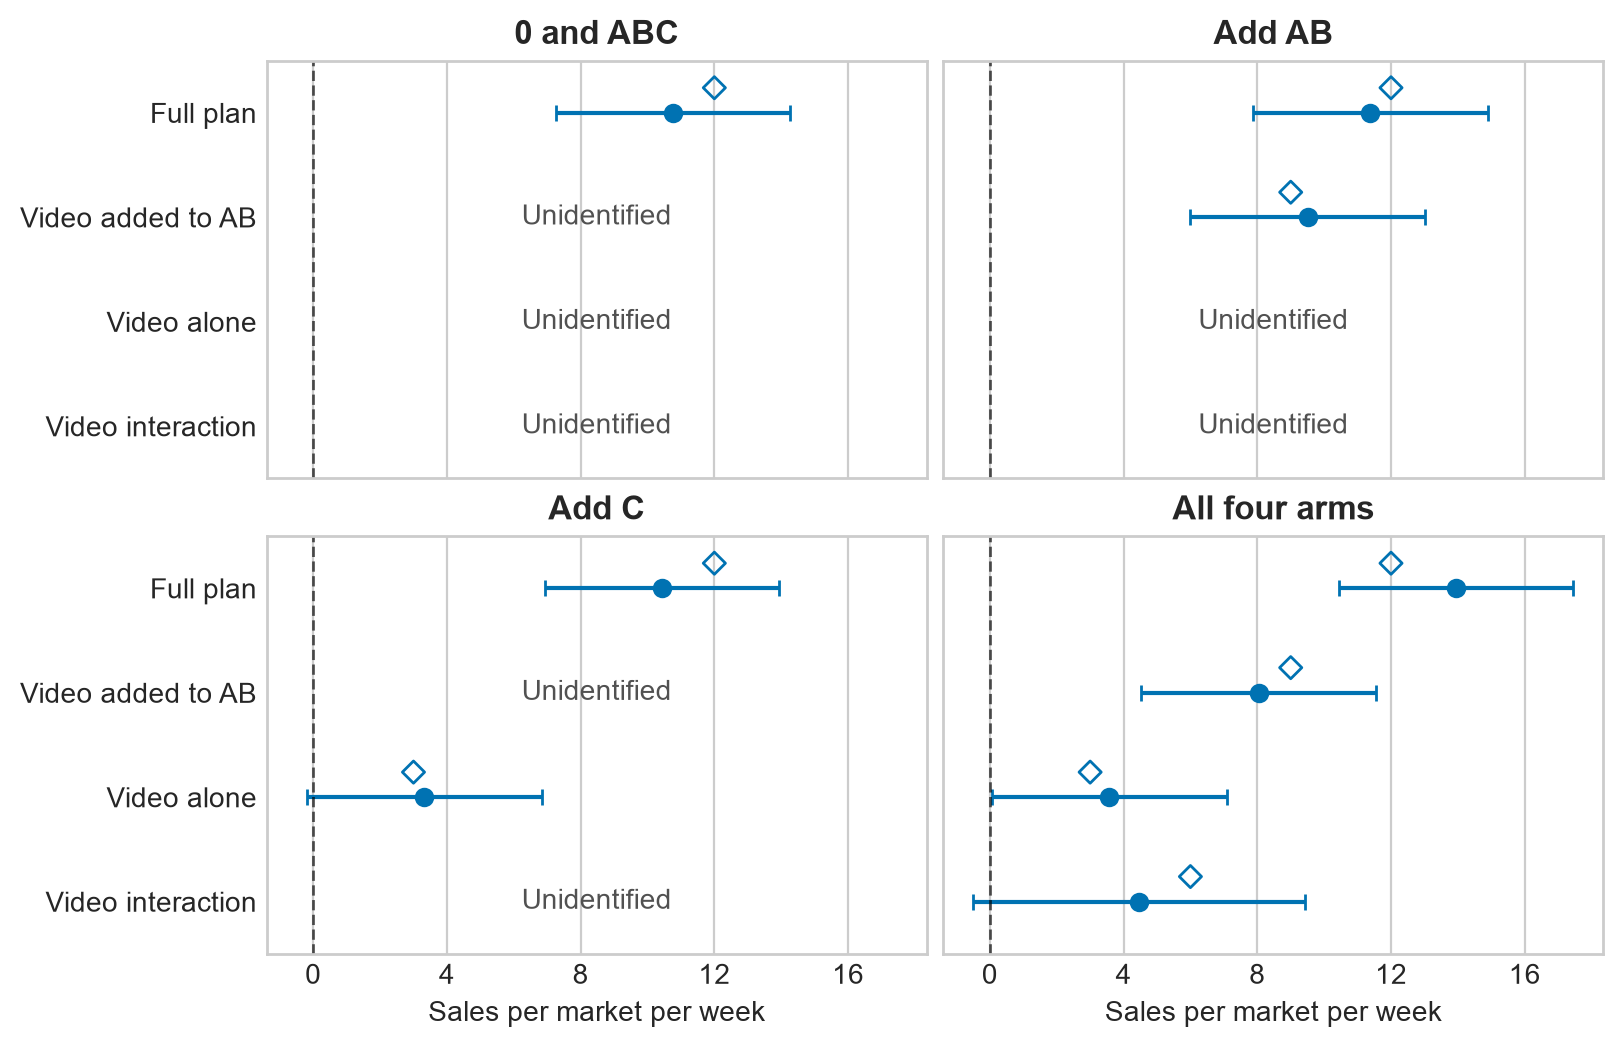

In [4]:
truths = {
    "Full plan": 12,
    "Video added to AB": 9,
    "Video alone": 3,
    "Video interaction": 6,
}
rng = np.random.default_rng(GEO_SEED)
fig, axes = plt.subplots(
    2,
    2,
    sharex=True,
    sharey=True,
    figsize=(FIG_WIDTH, 1.6 * FIG_HEIGHT),
    layout="constrained",
)
for ax, (design, arms) in zip(axes.flat, designs.items(), strict=True):
    estimates = estimate_contrasts(simulate_markets(arms, rng))
    for row, contrast in enumerate(contrasts):
        if contrast not in estimates:
            ax.text(
                0.5,
                row,
                "Unidentified",
                ha="center",
                va="center",
                color="#515151",
                transform=ax.get_yaxis_transform(),
            )
            continue
        mean, lower, upper = estimates[contrast]
        ax.errorbar(
            mean,
            row,
            xerr=[[mean - lower], [upper - mean]],
            fmt="o",
            color=ESTIMATE_COLOR,
            capsize=3,
        )
        ax.scatter(
            truths[contrast],
            row - 0.24,
            marker="D",
            facecolors="none",
            edgecolors=ESTIMATE_COLOR,
            s=32,
            zorder=3,
        )
    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.65)
    ax.set_title(design, fontweight="bold")
    ax.set_yticks(range(len(contrasts)), list(contrasts))
    ax.set_ylim(len(contrasts) - 0.5, -0.5)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
    ax.grid(axis="y", visible=False)
for ax in axes[-1]:
    ax.set_xlabel("Sales per market per week")
plt.show()

Buying video alongside the reallocation compares the full plan with $AB$. Buying video on its own compares $C$ with usual spend. The four-arm trial shows both increments and how much they differ. These endpoint comparisons measure the specified spend plans at the specified amounts.

### What if all markets get the same sales shock?

Take one four-arm trial and give each market eight extra sales per week during the launch window. This is the same common shock that inflated the national observed gap. The concurrent usual-spend group experiences it too. Keep the assignments and market noise fixed and estimate the contrasts again.

In [5]:
def add_common_shock(markets):
    return markets.assign(**{"Weekly sales": markets["Weekly sales"] + COMMON_SHOCK})


markets = simulate_markets(designs["All four arms"], rng)
full_plan = estimate_contrasts(markets)["Full plan"]
with_shock = estimate_contrasts(add_common_shock(markets))["Full plan"]
np.testing.assert_allclose(with_shock, full_plan, rtol=0, atol=1e-10)
display(
    pd.DataFrame(
        [full_plan, with_shock],
        index=["No shock", "Common shock"],
        columns=["Mean full-plan lift", "95% lower", "95% upper"],
    ).round(2)
)

,Mean full-plan lift,95% lower,95% upper
No shock,9.34,5.83,12.84
Common shock,9.34,5.83,12.84


The full-plan contrast and its interval stay the same in sales per market per week because the +8 raises both compared arm means equally. A shock that varies by arm would require separate consideration.

### Check recovery across independent trials

Run 2,000 independent datasets per design. Bias and MCSE use one posterior mean per simulated dataset. Coverage is the fraction of these datasets whose 95% credible interval contains the planted contrast. We expect 95% coverage under the stipulated Gaussian sampling model. The checks compare the estimated means with the planted values within three MCSEs and coverage with 95% within three binomial standard errors. The common-shock row reuses the four-arm assignments and outcomes with the shift applied.

In [6]:
simulation_rows = []
for design, arms in designs.items():
    for _ in range(N_REPLICATIONS):
        markets = simulate_markets(arms, rng)
        estimates = estimate_contrasts(markets)
        for contrast, (mean, lower, upper) in estimates.items():
            simulation_rows.append((design, contrast, mean, lower, upper))
        if design == "All four arms":
            shocked = estimate_contrasts(add_common_shock(markets))["Full plan"]
            np.testing.assert_allclose(
                shocked, estimates["Full plan"], rtol=0, atol=1e-10
            )
            simulation_rows.append(("All four + shock", "Full plan", *shocked))

In [7]:
trials = pd.DataFrame(
    simulation_rows, columns=["Design", "Contrast", "Estimate", "Lower", "Upper"]
)
trials["Truth"] = trials["Contrast"].map(truths)
trials["Covered"] = trials["Truth"].between(trials["Lower"], trials["Upper"])
trials["Width"] = trials["Upper"] - trials["Lower"]
scores = trials.groupby(["Design", "Contrast"], sort=False).agg(
    Mean=("Estimate", "mean"),
    Truth=("Truth", "first"),
    MCSE=("Estimate", "sem"),
    Coverage=("Covered", "mean"),
    Mean_width=("Width", "mean"),
)
scores.insert(2, "Bias", scores["Mean"] - scores["Truth"])
coverage_se = np.sqrt(INTERVAL_PROB * (1 - INTERVAL_PROB) / N_REPLICATIONS)
assert (scores["Bias"].abs() <= 3 * scores["MCSE"]).all()
assert ((scores["Coverage"] - INTERVAL_PROB).abs() <= 3 * coverage_se).all()
video_rows = scores.xs("All four arms").loc[["Video alone", "Video added to AB"]]
assert (
    6 * video_rows["MCSE"].max() < truths["Video added to AB"] - truths["Video alone"]
)
display(
    scores.assign(Coverage=100 * scores["Coverage"])
    .rename(columns={"Mean_width": "Mean 95% width", "Coverage": "95% coverage (%)"})
    .round(2)
)

Mean  Truth  Bias  MCSE  \
Design           Contrast                                      
0 and ABC        Full plan          12.03     12  0.03  0.04   
Add AB           Full plan          11.99     12 -0.01  0.04   
                 Video added to AB   9.00      9  0.00  0.04   
Add C            Full plan          12.05     12  0.05  0.04   
                 Video alone         3.04      3  0.04  0.04   
All four arms    Full plan          12.04     12  0.04  0.04   
                 Video added to AB   9.00      9 -0.00  0.04   
                 Video alone         3.04      3  0.04  0.04   
                 Video interaction   5.96      6 -0.04  0.06   
All four + shock Full plan          12.04     12  0.04  0.04   

                                    95% coverage (%)  Mean 95% width  
Design           Contrast                                             
0 and ABC        Full plan                     95.00            7.01  
Add AB           Full plan                     95.00            7.01  
                 Video added to AB             94.95            7.01  
Add C            Full plan                     94.15            7.01  
                 Video alone                   94.50            7.01  
All four arms    Full plan                     94.60            7.01  
                 Video added to AB             94.80            7.01  
                 Video alone                   95.25            7.01  
                 Video interaction             95.05            9.92  
All four + shock Full plan                     94.60            7.01

The table reports recovery and 95% interval coverage for the randomized geo contrasts. Means, errors and interval widths are in sales per market per week. The two video increments recover different targets. The interaction interval is wider because it carries uncertainty from four arm means. In the common-shock row, the full-plan contrast still recovers 12.

## Inspect gaps for individual treated markets

Arm comparisons answer the assignment questions. For a separate look at individual markets, simulate a small weekly panel with 52 pre-launch weeks and the same 12-week launch window. Three markets stay at usual spend, and two run the full plan. The unchanged markets share an overall trend and demand cycle but differ in level and seasonal patterns. In the simulator, each treated market's usual-spend mean is a different weighted combination of the three unchanged trajectories. The fit must learn those weights from the pre-launch outcomes. Each treated market has a planted +12 sales per week.

Fit one public PyMC {term}`synthetic control` with both treated markets. Its {term}`donor pool` contains only usual-spend markets. The pre-period helps you judge how well the donor-weighted {term}`counterfactual` tracks each treated market before launch. {cite:p}`abadie2021using`

In [8]:
panel_rng = np.random.default_rng(PANEL_SEED)
weeks = np.arange(-52, POST_WEEKS)
donors = ["Market A", "Market B", "Market C"]
treated_markets = ["Market D", "Market E"]
common_sales = 100 + weeks / 10 + 5 * np.sin(2 * np.pi * weeks / 13)
donor_means = np.column_stack(
    [
        common_sales - 6 + 2 * np.cos(2 * np.pi * weeks / 13),
        common_sales + 4 * np.sin(2 * np.pi * weeks / 7),
        common_sales + 6,
    ]
)
treated_means = donor_means @ np.array([[0.5, 0.2], [0.35, 0.3], [0.15, 0.5]])
weekly_means = np.column_stack([donor_means, treated_means])
sales = weekly_means + panel_rng.normal(0, 0.5, weekly_means.shape)
panel = pd.DataFrame(sales, index=weeks, columns=donors + treated_markets)
panel.loc[weeks >= 0, treated_markets] += truths["Full plan"]

In [9]:
synthetic_control = cp.SyntheticControl(
    panel,
    treatment_time=0,
    control_units=donors,
    treated_units=treated_markets,
    model=cp.pymc_models.WeightedSumFitter(
        sample_kwargs={"random_seed": FIT_SEED, "progressbar": False}
    ),
)

In [10]:
synthetic_control.fit();

**Figure.** Observed sales for each full-plan market together with the posterior mean and pointwise 94% highest density interval for expected sales under usual spend. The launch line separates pre-period fit from the post-launch observed gaps.

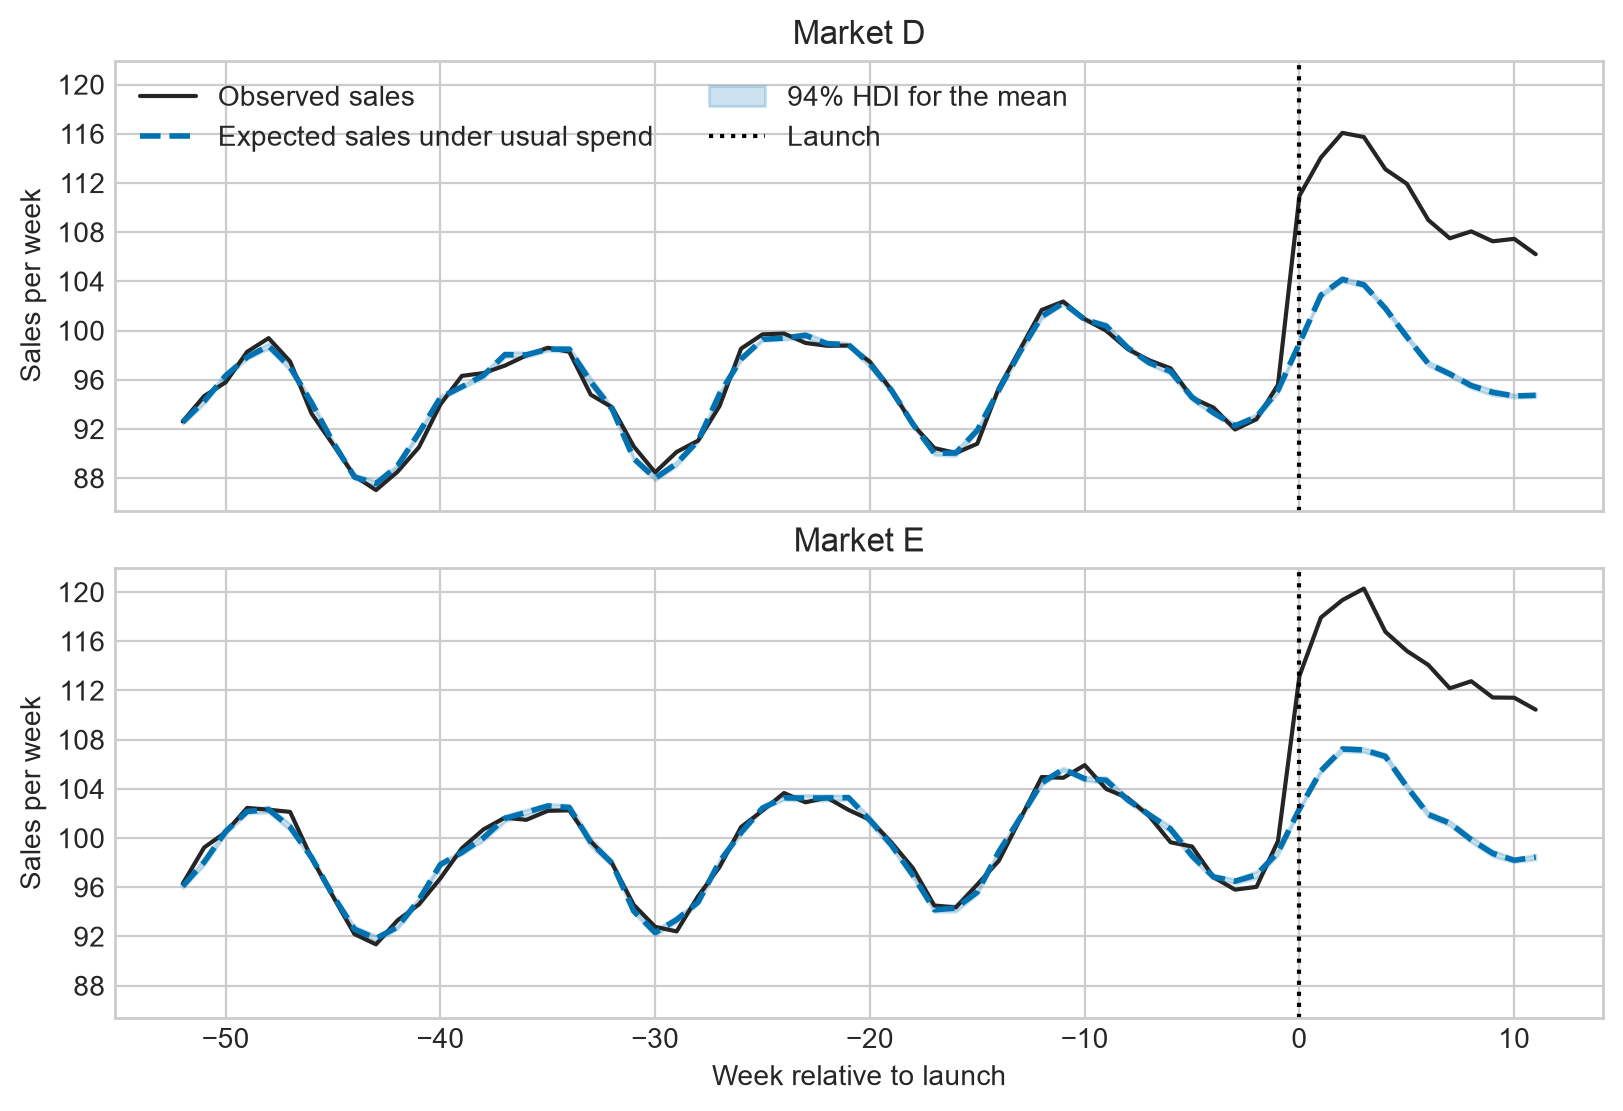

In [11]:
fig, axes = plt.subplots(
    2,
    1,
    sharex=True,
    sharey=True,
    figsize=(FIG_WIDTH, 1.7 * FIG_HEIGHT),
    layout="constrained",
)
for market, ax in zip(treated_markets, axes, strict=True):
    plot_data = synthetic_control.get_plot_data(treated_unit=market)
    ax.plot(
        plot_data.index, plot_data[market], color=OBSERVED_COLOR, label="Observed sales"
    )
    ax.plot(
        plot_data.index,
        plot_data["prediction"],
        linestyle="--",
        lw=2,
        color=ESTIMATE_COLOR,
        label="Expected sales under usual spend",
    )
    ax.fill_between(
        plot_data.index,
        plot_data["pred_hdi_lower_94"],
        plot_data["pred_hdi_upper_94"],
        alpha=0.20,
        color=ESTIMATE_COLOR,
        label="94% HDI for the mean",
    )
    ax.axvline(0, color="black", linestyle=":", label="Launch")
    ax.set(title=market, ylabel="Sales per week")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(ncols=2, loc="upper left")
axes[-1].set_xlabel("Week relative to launch")
plt.show()

In [12]:
gap = synthetic_control.result.impact_post.mean("obs_ind")
market_gaps = gap.mean(("chain", "draw")).to_series().rename("Mean observed gap")
display(market_gaps.to_frame().assign(**{"Planted lift": truths["Full plan"]}).round(2))

,Mean observed gap,Planted lift
treated_units,,
Market D,11.88,12
Market E,11.96,12


Each post-launch **observed gap** is realized sales minus modeled usual-spend sales. The table averages it over the launch weeks, in sales per week for each market. The fit supplies only an untreated expected trajectory. A model-based expected effect would also need a treated expected trajectory. The randomized arm contrasts above supply the evidence about adding video.

## Take the contrast back to your spend decision

Decide which plans the business could actually deliver and fund. If the question is whether to add video to the reallocation, assign both $ABC$ and $AB$. If the question is whether video works differently alongside the reallocation, include $C$ and usual spend too. The per-market estimate targets the enrolled markets. Scaling it to a national total requires an explicit assumption about how effects transport to other markets and how their sizes enter the total.

For one national launch, see the {doc}`national spend bundles example <interrupted-time-series-national-spend-bundles-pymc>`. For related designs, see {doc}`multi-cell geo lift <multi-cell-geolift>` and {doc}`up, down, and control geo lift <up-down-control-geolift-pymc>`. The fixed up, down and control arms and single-channel calibration export in `UpDownGeoLift` address a different treatment design.

## References

:::{bibliography}
:filter: docname in docnames
:::